In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
df = pd.read_csv("IPL_Moneyball_Merged_2008_2026.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully
Shape: (3311, 27)


,season,player,runs,balls_faced,innings,fours,sixes,dismissals,balls_bowled,runs_conceded,...,acquisition_type,base_price_lakh,final_price_lakh,bat_style,bowl_style,player_full_name,strike_rate,batting_avg,economy,bowling_avg
0,2008,A Chopra,42,52,5,5,0,5,0,0,...,NaN,NaN,NaN,Right hand Bat,"Right arm Medium, Right arm Offbreak",Aakash Chopra,80.77,8.40,NaN,NaN
1,2008,A Kumble,13,17,4,1,0,2,230,304,...,auction,NaN,125.0,Right hand Bat,Legbreak Googly,Anil Kumble,76.47,6.50,7.93,43.43
2,2008,A Mishra,37,42,3,3,0,3,119,138,...,NaN,NaN,NaN,Right hand Bat,Legbreak,Amit Mishra,88.10,12.33,6.96,12.55
3,2008,A Mukund,0,1,1,0,0,1,0,0,...,NaN,NaN,NaN,Left hand Bat,Legbreak Googly,Abhinav Mukund,0.00,0.00,NaN,NaN
4,2008,A Nehra,3,13,3,0,0,1,269,348,...,auction,NaN,100.0,Right hand Bat,Left arm Medium fast,Ashish Nehra,23.08,3.00,7.76,29.00


In [4]:
numeric_cols = df.select_dtypes(include=np.number).columns

print("Numerical Summary:")
print(df[numeric_cols].describe())

Numerical Summary:
            season         runs  balls_faced      innings        fours  \
count  3311.000000  3311.000000  3311.000000  3311.000000  3311.000000   
mean   2017.180308   111.740260    84.116581     5.526729    10.100272   
std       5.591679   152.618255   108.881763     4.950675    14.948681   
min    2008.000000     0.000000     0.000000     0.000000     0.000000   
25%    2012.000000     4.000000     5.000000     1.000000     0.000000   
50%    2017.000000    34.000000    30.000000     4.000000     3.000000   
75%    2022.000000   179.000000   132.000000     9.000000    15.000000   
max    2026.000000   973.000000   640.000000    19.000000    88.000000   

             sixes   dismissals  balls_bowled  runs_conceded      wickets  \
count  3311.000000  3311.000000   3311.000000    3311.000000  3311.000000   
mean      4.568710     4.320749     83.756267     115.550891     3.960435   
std       7.232691     4.362480    105.775668     140.333831     5.706408   
min   

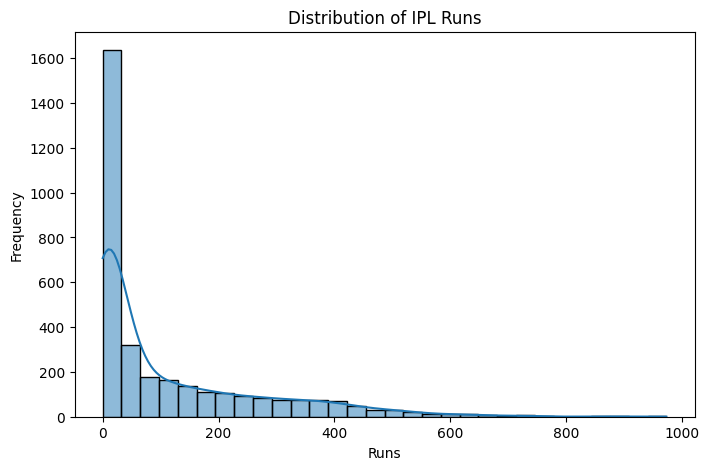

In [3]:
plt.figure(figsize=(8, 5))

sns.histplot(df["runs"].dropna(), bins=30, kde=True)

plt.title("Distribution of IPL Runs")
plt.xlabel("Runs")
plt.ylabel("Frequency")

plt.show()

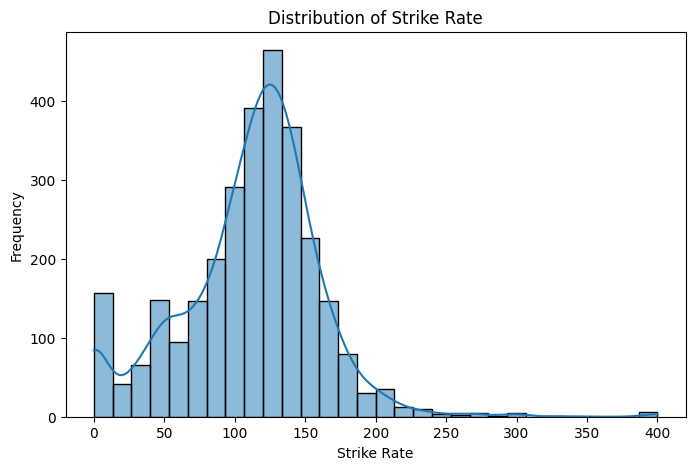

In [5]:
plt.figure(figsize=(8, 5))

sns.histplot(df["strike_rate"].dropna(), bins=30, kde=True)

plt.title("Distribution of Strike Rate")
plt.xlabel("Strike Rate")
plt.ylabel("Frequency")

plt.show()

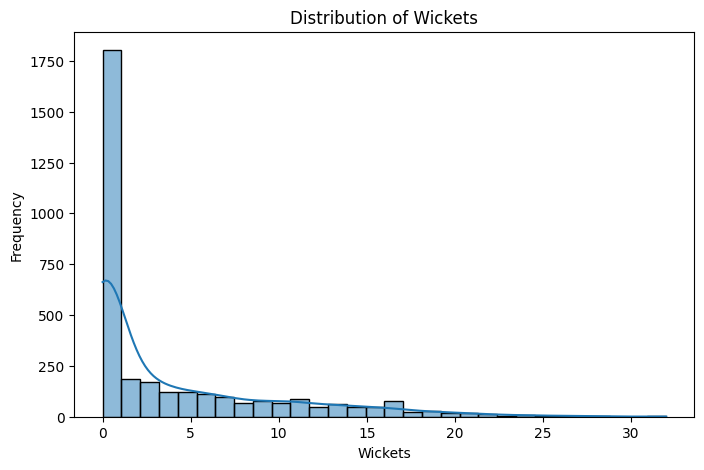

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(df["wickets"].dropna(), bins=30, kde=True)

plt.title("Distribution of Wickets")
plt.xlabel("Wickets")
plt.ylabel("Frequency")

plt.show()

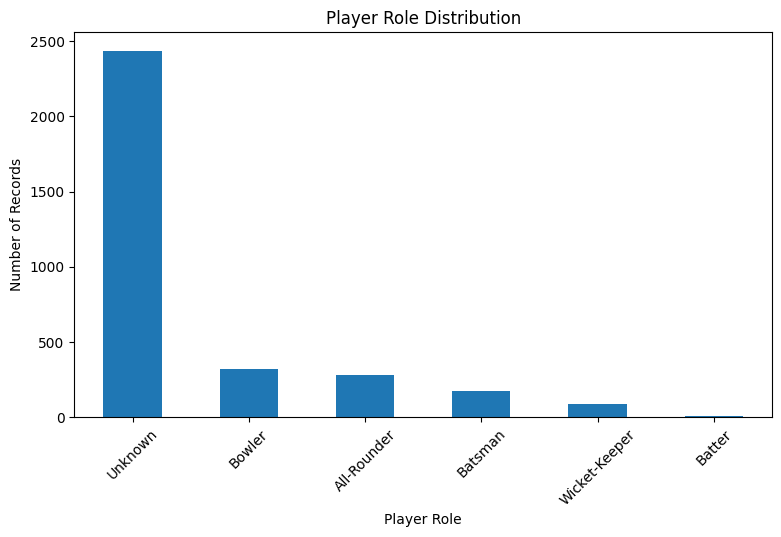

In [7]:
plt.figure(figsize=(9, 5))

df["role"].fillna("Unknown").value_counts().plot(
    kind="bar"
)

plt.title("Player Role Distribution")
plt.xlabel("Player Role")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)
plt.show()

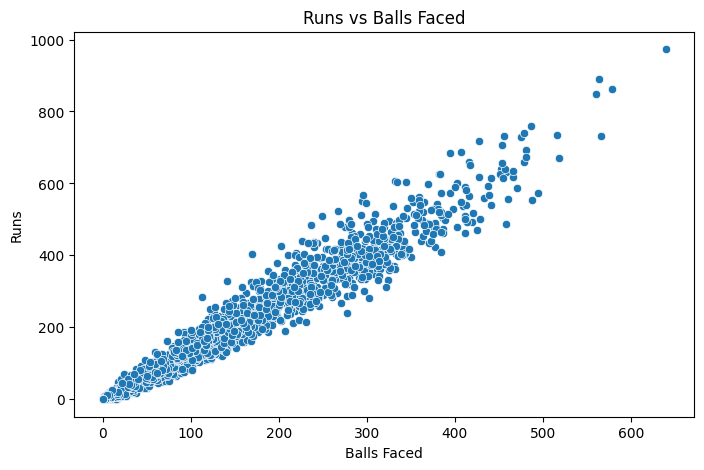

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="balls_faced",
    y="runs"
)

plt.title("Runs vs Balls Faced")
plt.xlabel("Balls Faced")
plt.ylabel("Runs")

plt.show()

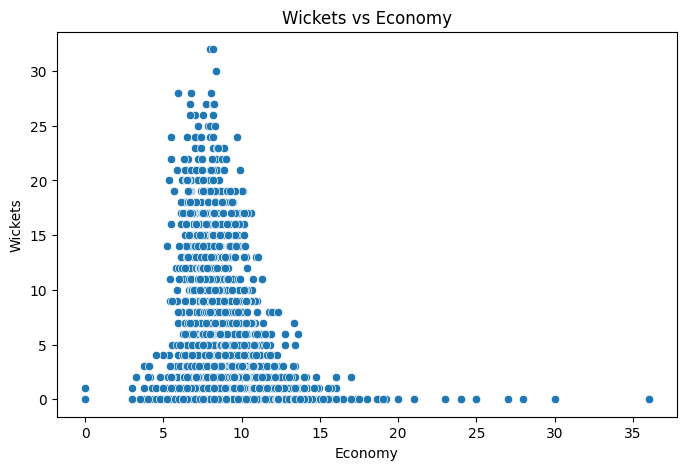

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="economy",
    y="wickets"
)

plt.title("Wickets vs Economy")
plt.xlabel("Economy")
plt.ylabel("Wickets")

plt.show()

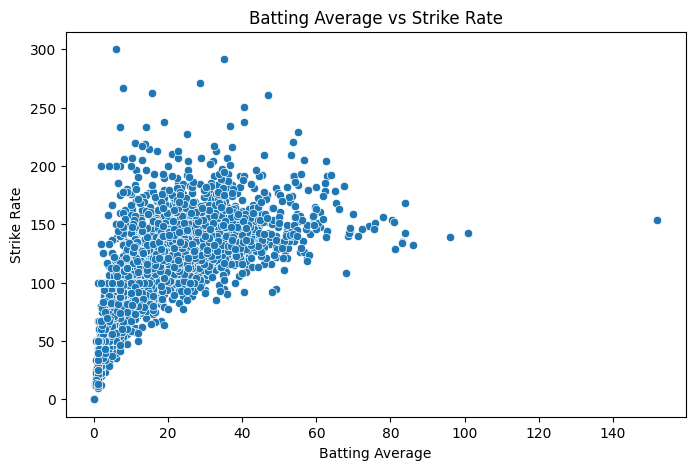

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="batting_avg",
    y="strike_rate"
)

plt.title("Batting Average vs Strike Rate")
plt.xlabel("Batting Average")
plt.ylabel("Strike Rate")

plt.show()

In [11]:
correlation = df[numeric_cols].corr()

print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
                    season      runs  balls_faced   innings     fours  \
season            1.000000  0.024786    -0.022940 -0.021439  0.006911   
runs              0.024786  1.000000     0.983936  0.887113  0.964513   
balls_faced      -0.022940  0.983936     1.000000  0.900703  0.955956   
innings          -0.021439  0.887113     0.900703  1.000000  0.837439   
fours             0.006911  0.964513     0.955956  0.837439  1.000000   
sixes             0.111682  0.885043     0.814522  0.773659  0.778748   
dismissals       -0.018249  0.885555     0.904083  0.955724  0.862976   
balls_bowled     -0.023427 -0.262037    -0.266176 -0.116286 -0.273802   
runs_conceded     0.027684 -0.277691    -0.284024 -0.139892 -0.289642   
wickets           0.002837 -0.248892    -0.254715 -0.122747 -0.257687   
matches_bowled   -0.031143 -0.223910    -0.228911 -0.064986 -0.247694   
base_price_lakh   0.028805  0.370286     0.382312  0.409027  0.342819   
final_price_lakh  0.294037  0.3

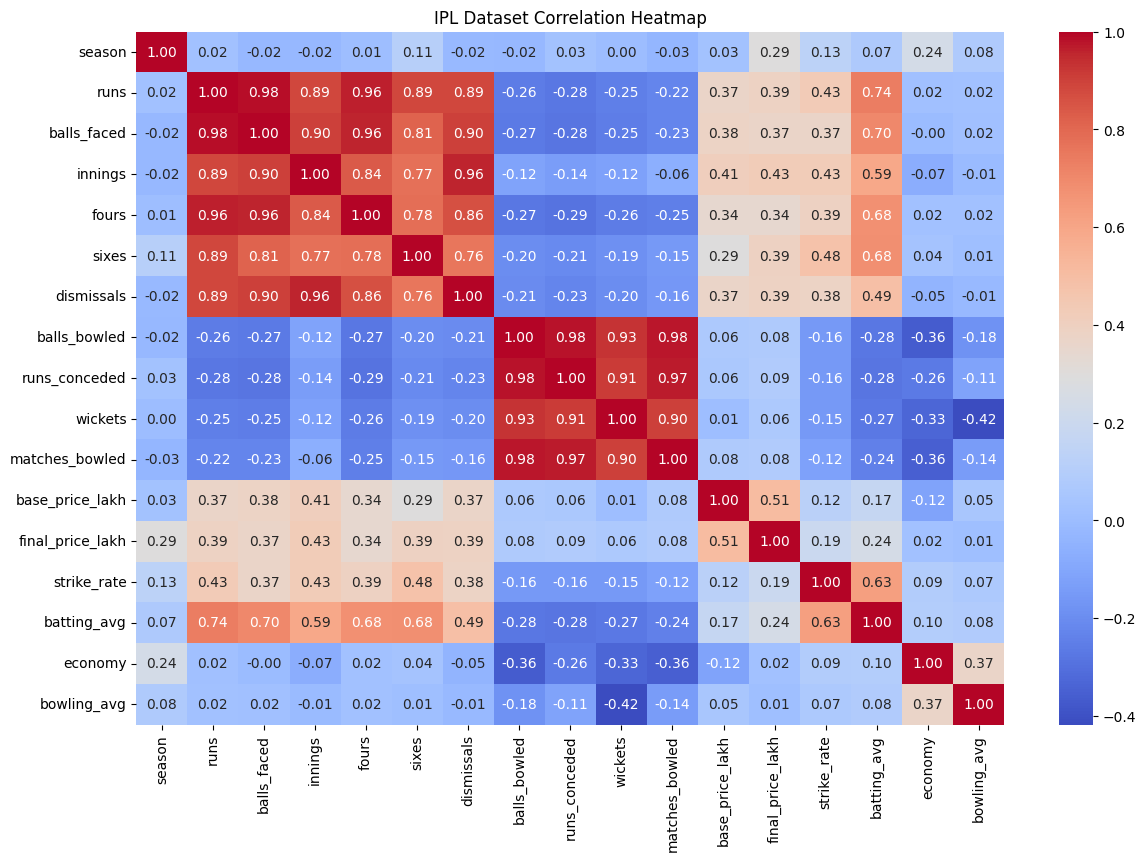

In [12]:
plt.figure(figsize=(14, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("IPL Dataset Correlation Heatmap")

plt.show()

In [13]:
distribution = pd.DataFrame({
    "Skewness": df[numeric_cols].skew(),
    "Kurtosis": df[numeric_cols].kurt()
})

print(distribution)

                  Skewness   Kurtosis
season           -0.028852  -1.301072
runs              1.630327   2.284141
balls_faced       1.542916   1.821738
innings           0.707915  -0.784502
fours             1.886722   3.426693
sixes             2.224276   5.931710
dismissals        0.910553  -0.311549
balls_bowled      1.208760   0.279334
runs_conceded     1.118954   0.077647
wickets           1.635061   2.170759
matches_bowled    0.973742  -0.324413
base_price_lakh   0.996718  -0.126320
final_price_lakh  1.682410   2.738704
strike_rate       0.124136   2.575688
batting_avg       1.185638   3.298108
economy           2.718052  17.061987
bowling_avg       2.774680  11.769463


In [14]:
print("WEEK 04 - FINAL EDA SUMMARY")

print("Dataset Shape:", df.shape)

print("\nNumerical Columns:")
print(len(numeric_cols))

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nUnivariate and Bivariate Analysis Completed")

WEEK 04 - FINAL EDA SUMMARY
Dataset Shape: (3311, 27)

Numerical Columns:
17

Missing Values:
17839

Duplicate Records:
0

Univariate and Bivariate Analysis Completed
